# Triangulation

Triangulate points to create sparse "point cloud" 3D model.

In [4]:
!curl.exe -L -o left.jpeg https://raw.githubusercontent.com/rafpug/StereoTriangulation/main/IMG_1559.jpeg
!curl.exe -L -o right.jpeg https://raw.githubusercontent.com/rafpug/StereoTriangulation/main/IMG_1560.jpeg

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100  2.58M 100  2.58M   0      0 15.36M      0                              0
100  2.58M 100  2.58M   0      0 15.34M      0                              0
100  2.58M 100  2.58M   0      0 15.33M      0                              0
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100  2.41M 100  2.41M   0      0  4.70M      0                              0
100  2.41M 100  2.41M   0      0  4.70M      0                              0
100  2.41M 100  2.41M   0      0  4.70M      0                              0


In [6]:
!pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import numpy as np
from matplotlib import pyplot as plt
import tqdm
from skimage.feature import plot_matched_features
import cv2

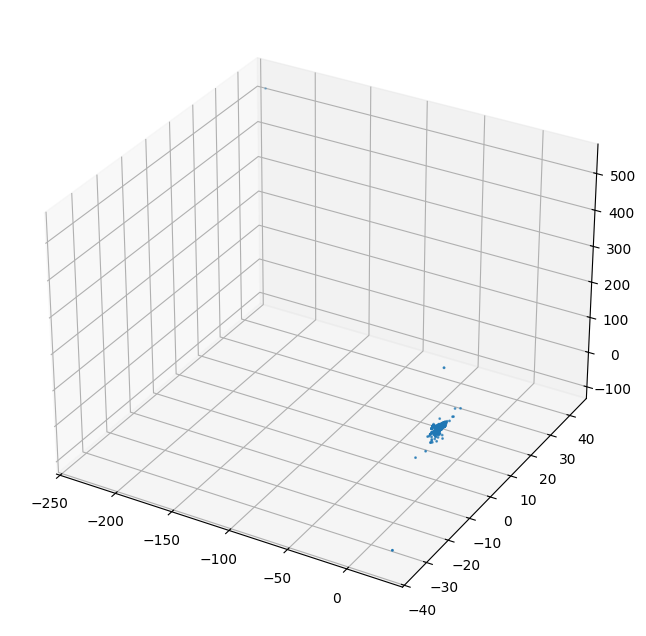

In [11]:
left = cv2.imread("left.jpeg")
right = cv2.imread("right.jpeg")

left_gray = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
keypoints_left, descriptors_left = sift.detectAndCompute(left_gray, None)
keypoints_right, descriptors_right = sift.detectAndCompute(right_gray, None)

matcher = cv2.BFMatcher()
matches = matcher.knnMatch(descriptors_left, descriptors_right, k=2)

# Apply ratio test
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

mkpl = np.float32([keypoints_left[m.queryIdx].pt for m in good_matches])
mkpr = np.float32([keypoints_right[m.trainIdx].pt for m in good_matches])

K = np.array([
    [3280,    0, 2016],
    [   0, 3280, 1512],
    [   0,    0,    1]
], dtype=np.float64)

E, mask = cv2.findEssentialMat(mkpl, mkpr, K, method=cv2.RANSAC, prob=0.999, threshold=1.0)
_, R, t, mask_pose = cv2.recoverPose(E, mkpl, mkpr, K)

# Triangulate points
proj_matrix_left = K @ np.hstack((np.eye(3), np.zeros((3, 1))))
proj_matrix_right = K @ np.hstack((R, t))
points_4d_hom = cv2.triangulatePoints(proj_matrix_left, proj_matrix_right, mkpl.T, mkpr.T)
points_3d = (points_4d_hom[:3] / points_4d_hom[3]).T

with open("point_cloud.obj", "w") as file:
    for x, y, z in points_3d:
        file.write(f"v {x} {y} {z}\n")

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(points_3d[:, 0], points_3d[:, 1], points_3d[:, 2], s=1)
plt.show()
